# Notebook 04 (4-layer benchmark) — Training of the 4-Layer Architecture Grid

**Track A extension · Soccer Event Transformer · Identity × Context project**

| Item | Content |
|---|---|
| **Research question (benchmark)** | Given that the originally proposed architecture used 4 layers and 4 heads, how does the 4-layer family behave when head count and context length are varied, and which 4-layer configuration should be carried forward? |
| **Purpose of this notebook** | Train every configuration of the 4-layer grid (3 head counts × 3 context lengths × 3 seeds = 27 runs) under the unchanged Track A training procedure, and record the seed-level results. |
| **Relation to Track A notebook 04** | The original notebook 04 selected the learning rate and weight decay and trained the MLP baseline. That search is not repeated: the selected values are inherited unchanged, so that the grid varies only the architecture. The re-run of the original 4L × 4H × K32 configuration takes the place of the original pilot run. |
| **Test data** | Not used. |


In [2]:
# ---------------------------------------------------------------------------
# Environment setup (identical at the top of every 4-layer benchmark notebook)
# ---------------------------------------------------------------------------
import os
import sys
import json
import time
import hashlib
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

PROJECT_DIR = Path(os.environ.get("TRACK_A_DIR", "/content/drive/MyDrive/soccer_mi/track_a"))
RUN_MODE = os.environ.get("TRACK_A_RUN_MODE", "full")      # "full" = research runs, "smoke" = code check only
assert RUN_MODE in ("full", "smoke")
os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

# Existing Track A outputs. These are read, never written.
EXISTING_DIR = PROJECT_DIR if RUN_MODE == "full" else PROJECT_DIR / "smoke"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
EXISTING_RUNS_DIR = EXISTING_DIR / "runs"
EXISTING_RESULTS_DIR = EXISTING_DIR / "results"
EXISTING_FROZEN_CONFIG = EXISTING_DIR / "config" / "frozen_config.json"
EXISTING_BASELINE_FILE = PROJECT_DIR / "results" / "baselines_validation.json"

# All outputs of the 4-layer benchmark are written below BENCH_DIR only.
BENCH_DIR = EXISTING_DIR / "benchmarks" / "track_a_4layer"
RUNS_DIR = BENCH_DIR / "runs"
RESULTS_DIR = BENCH_DIR / "results"
FIGURES_DIR = BENCH_DIR / "figures"
CONFIG_DIR = BENCH_DIR / "config"
MANIFEST_DIR = BENCH_DIR / "manifests"
LOG_DIR = BENCH_DIR / "logs"
for folder in [RUNS_DIR, RESULTS_DIR, FIGURES_DIR, CONFIG_DIR, MANIFEST_DIR, LOG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
MANIFEST_PATH = MANIFEST_DIR / "experiment_manifest.jsonl"

print("Colab:", IN_COLAB, "| RUN_MODE:", RUN_MODE)
print("Existing Track A outputs (read-only):", EXISTING_DIR)
print("Benchmark outputs:", BENCH_DIR)

Mounted at /content/drive
Colab: True | RUN_MODE: full
Existing Track A outputs (read-only): /content/drive/MyDrive/soccer_mi/track_a
Benchmark outputs: /content/drive/MyDrive/soccer_mi/track_a/benchmarks/track_a_4layer


In [3]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import importlib
from scipy import stats

# The Track A modules are imported, never rewritten. The benchmark therefore runs on
# exactly the code that produced the existing Track A results.
import src.data as data
import src.batching as batching
import src.metrics as metrics
import src.model as model_module
import src.mlp_baseline as mlp_baseline
import src.training as training
import src.analysis as analysis
for module in [data, batching, metrics, model_module, mlp_baseline, training, analysis]:
    importlib.reload(module)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if RUN_MODE == "full" and DEVICE != "cuda":
    raise RuntimeError("BLOCKED: full-mode training requires a GPU. In Colab: Runtime > Change runtime type > GPU.")

events = pd.read_parquet(ARTIFACTS_DIR / "events_prepared.parquet")
targets = events["action_id"].to_numpy().astype("int64")
match_ids = events["match_id"].to_numpy()

with open(EXISTING_FROZEN_CONFIG) as handle:
    EXISTING_FROZEN = json.load(handle)
with open(EXISTING_RESULTS_DIR / "04_selected_hyperparameters.json") as handle:
    EXISTING_HYPERPARAMETERS = json.load(handle)

# Settings shared by every benchmark run: taken from the frozen Track A configuration.
ENCODING = EXISTING_FROZEN["encoding"]
POSSESSION_FEATURES = EXISTING_FROZEN["possession_features"]
STRIDE = EXISTING_FROZEN["stride"]
LEARNING_RATE = EXISTING_HYPERPARAMETERS["learning_rate"]
WEIGHT_DECAY = EXISTING_HYPERPARAMETERS["weight_decay"]
EPOCH_BUDGET = EXISTING_HYPERPARAMETERS["epoch_budget"]
D_MODEL = 128
D_FF = 512


def transformer_config(seed, n_layers, n_heads, context_length, use_groups=None):
    """Run configuration in exactly the format used by Track A notebooks 04-06."""
    model = {"n_layers": n_layers, "n_heads": n_heads, "d_model": D_MODEL, "d_ff": D_FF}
    if use_groups is not None:
        model["use_groups"] = list(use_groups)
    config = {"model_type": "transformer", "encoding": ENCODING, "possession_features": POSSESSION_FEATURES,
              "context_length": context_length, "stride": STRIDE, "seed": seed, "model": model,
              "training": {"learning_rate": LEARNING_RATE, "weight_decay": WEIGHT_DECAY, "max_epochs": EPOCH_BUDGET}}
    return config


def config_id(n_layers, n_heads, context_length, seed=None):
    """Readable identifier, e.g. 4L_2H_K32_seed0."""
    label = f"{n_layers}L_{n_heads}H_K{context_length}"
    if seed is not None:
        label = label + f"_seed{seed}"
    return label


def bundle_for(context_length, encoding=None):
    if encoding is None:
        encoding = ENCODING
    return training.prepare_data(events, ARTIFACTS_DIR, encoding, POSSESSION_FEATURES, context_length, STRIDE,
                                 DEVICE, RUN_MODE)


def benchmark_run_dir(config):
    return RUNS_DIR / training.run_name_for(config)


def existing_run_dir(config):
    return EXISTING_RUNS_DIR / training.run_name_for(config)


def train_benchmark_run(config, keep_every_epoch=False):
    """Train (or load, if already finished) one benchmark run. Output goes to the benchmark folder only."""
    result = training.train_run(config, bundle_for(config["context_length"]), RUNS_DIR, MANIFEST_PATH,
                                keep_every_epoch=keep_every_epoch)
    return RUNS_DIR / result["run_name"]


def run_record(run_dir, label, source):
    """One row of seed-level results from a finished run folder."""
    result = analysis.load_final_results(run_dir)
    config = result["run_config"]
    val = result["val_metrics"]
    return {"source": source, "label": label,
            "layers": config["model"]["n_layers"], "heads": config["model"]["n_heads"],
            "d_head": config["model"]["d_model"] // config["model"]["n_heads"],
            "d_model": config["model"]["d_model"], "d_ff": config["model"]["d_ff"],
            "K": config["context_length"], "seed": config["seed"],
            "parameters": result["parameter_counts"]["total"],
            "best_epoch": result["best_epoch"], "epochs_run": result["epochs_run"],
            "val_nll": val["nll"], "val_accuracy": val["accuracy"], "val_macro_f1": val["macro_f1"],
            "val_top3": val["top3_accuracy"], "val_top5": val["top5_accuracy"], "val_ece": val["ece"],
            "train_nll": result["train_nll"], "training_minutes": result["runtime_seconds"] / 60,
            "run_dir": str(run_dir)}


def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        while True:
            block = handle.read(1024 * 1024)
            if not block:
                break
            digest.update(block)
    return digest.hexdigest()


print(f"Settings inherited from Track A: encoding {ENCODING}, possession features {POSSESSION_FEATURES}, "
      f"stride {STRIDE}, learning rate {LEARNING_RATE:g}, weight decay {WEIGHT_DECAY:g}, epoch budget {EPOCH_BUDGET}")
print("Device:", DEVICE)

Settings inherited from Track A: encoding T300, possession features pre_action, stride 8, learning rate 0.0003, weight decay 0.1, epoch budget 30
Device: cuda


## 1. Terms used in this notebook

| Term | Meaning in this benchmark |
|---|---|
| **Layer** | One Transformer block: causal self-attention followed by an MLP, each wrapped in a pre-LayerNorm residual connection. All models in this benchmark have 4 layers. |
| **Attention head** | An independent attention computation within a layer. Each head computes its own attention pattern and writes its own output. |
| **Head dimension (d_head)** | The width of each head's query, key and value vectors. With a fixed residual width d_model = 128, the head dimension is 128 divided by the number of heads: 64 for 2 heads, 32 for 4 heads, 16 for 8 heads. Changing the head count therefore changes how the same attention width is divided, not the total width or the parameter count. |
| **Context length (K)** | The number of consecutive events in one input window. A prediction at position *i* can use at most *i* earlier events of the same window. The benchmark tests K = 16, 32 and 64. |
| **Causal masking** | Attention scores for later positions are set to minus infinity before the softmax, so that no position can use information from events after it. |
| **Seed** | The number that fixes the random initialisation and the order of training windows. Different seeds of the same configuration show how much a result varies by chance. |
| **Validation NLL** | The mean negative log-likelihood of the observed action on the validation split, each event scored once. It is the primary metric of Track A; section 5 of benchmark notebook 05 defines all metrics in full. |
| **Checkpoint** | A saved copy of the model weights. The checkpoint with the lowest validation NLL during training is kept (`best.pt`). |

## 2. Settings inherited from Track A

The benchmark changes only the number of heads and the context length. Every other setting is read from the files written by the Track A notebooks, so that no value is re-typed by hand:

* the player encoding, possession features and window stride come from the frozen Track A configuration;
* the learning rate, weight decay and epoch budget come from the Track A hyperparameter selection;
* the model code, training procedure, checkpoint rule and metric functions are the Track A modules in `src/`, imported without modification.

The input features are those of the current Track A model. The `play_pattern` input is not part of any model input group in `src/model.py`; the check below confirms this.

In [4]:
inherited = pd.DataFrame([
    ("player encoding", ENCODING, "config/frozen_config.json"),
    ("possession features", POSSESSION_FEATURES, "config/frozen_config.json"),
    ("window stride", STRIDE, "config/frozen_config.json"),
    ("learning rate", LEARNING_RATE, "results/04_selected_hyperparameters.json"),
    ("weight decay", WEIGHT_DECAY, "results/04_selected_hyperparameters.json"),
    ("epoch budget (early stopping patience 5)", EPOCH_BUDGET, "results/04_selected_hyperparameters.json"),
    ("batch size, warm-up, schedule, clipping, precision", "256 windows, 5% warm-up, cosine to 10%, clip 1.0, fp32",
     "src/training.py (DEFAULT_TRAINING)"),
    ("d_model / d_ff / activation / normalisation", "128 / 512 / GELU / pre-LayerNorm", "src/model.py"),
    ("checkpoint rule", "lowest validation NLL (best.pt)", "src/training.py"),
], columns=["setting", "value", "source"])

groups_using_play_pattern = []
for group_name, feature_names in model_module.FACTOR_GROUPS.items():
    if "play_pattern" in feature_names:
        groups_using_play_pattern.append(group_name)
print("Model input groups that contain play_pattern:", groups_using_play_pattern if groups_using_play_pattern else "none")
print("Training defaults in src/training.py:", {k: training.DEFAULT_TRAINING[k] for k in
      ["batch_size", "warmup_fraction", "min_lr_ratio", "grad_clip", "patience"]})
inherited

Model input groups that contain play_pattern: none
Training defaults in src/training.py: {'batch_size': 256, 'warmup_fraction': 0.05, 'min_lr_ratio': 0.1, 'grad_clip': 1.0, 'patience': 5}


,setting,value,source
0,player encoding,T300,config/frozen_config.json
1,possession features,pre_action,config/frozen_config.json
2,window stride,8,config/frozen_config.json
3,learning rate,0.0003,results/04_selected_hyperparameters.json
4,weight decay,0.1,results/04_selected_hyperparameters.json
5,epoch budget (early stopping patience 5),30,results/04_selected_hyperparameters.json
6,"batch size, warm-up, schedule, clipping, preci...","256 windows, 5% warm-up, cosine to 10%, clip 1...",src/training.py (DEFAULT_TRAINING)
7,d_model / d_ff / activation / normalisation,128 / 512 / GELU / pre-LayerNorm,src/model.py
8,checkpoint rule,lowest validation NLL (best.pt),src/training.py


## 3. Code compatibility

The benchmark is only comparable with the existing Track A results if the code used here computes the same model as the code that produced those results. Two checks establish this before any training.

1. **Architecture compatibility.** The primary checkpoint of the frozen Track A model is loaded into a model built by the current code with `strict=True`. Loading fails if any parameter name or shape differs.
2. **Numerical compatibility.** The validation logits of that checkpoint are recomputed and compared with the logits stored when the model was trained.

In addition, fingerprints (SHA-256) of the Track A result files are recorded, so that it can be verified at the end of the benchmark that the reference results were not modified.

In [5]:
with open(EXISTING_RESULTS_DIR / "06_validation_report.json") as handle:
    existing_validation_report = json.load(handle)
primary_run_dir = EXISTING_RUNS_DIR / existing_validation_report["primary_run"]
with open(primary_run_dir / "run_config.json") as handle:
    primary_config = json.load(handle)

primary_bundle = bundle_for(primary_config["context_length"], primary_config["encoding"])
primary_model = training.build_model(primary_config, primary_bundle["vocabulary_sizes"]).to(DEVICE)
state = torch.load(primary_run_dir / "best.pt", map_location=DEVICE)
primary_model.load_state_dict(state, strict=True)
recomputed_logits, _, recomputed_rows = training.predict_view(primary_model, primary_bundle, "val")
stored = np.load(primary_run_dir / "val_predictions.npz")
order_new = np.argsort(recomputed_rows)
order_stored = np.argsort(stored["event_rows"])
same_events = np.array_equal(recomputed_rows[order_new], stored["event_rows"][order_stored])
max_difference = float(np.abs(recomputed_logits[order_new] - stored["logits"][order_stored]).max())

compatibility = {
    "existing primary run": primary_run_dir.name,
    "checkpoint loads with strict=True": True,
    "parameter count (current code)": model_module.count_parameters(primary_model)["total"],
    "parameter count (recorded)": analysis.load_final_results(primary_run_dir)["parameter_counts"]["total"],
    "same validation events": bool(same_events),
    "max |recomputed - stored logit|": max_difference,
}
for key, value in compatibility.items():
    print(f"{key:36s} {value}")
if not same_events or compatibility["parameter count (current code)"] != compatibility["parameter count (recorded)"]:
    raise RuntimeError("The current code does not reproduce the existing Track A model. The benchmark is not comparable.")

existing primary run                 transformer_T300_pre_action_L2_H2_D128_F512_K16_g-all_lr0.0003_wd0.1_s104
checkpoint loads with strict=True    True
parameter count (current code)       514575
parameter count (recorded)           514575
same validation events               True
max |recomputed - stored logit|      0.0


In [6]:
source_fingerprints = {}
for file in sorted((PROJECT_DIR / "src").glob("*.py")):
    source_fingerprints[file.name] = file_sha256(file)

existing_files = []
for folder in [EXISTING_RESULTS_DIR, EXISTING_DIR / "config"]:
    for file in sorted(folder.rglob("*")):
        if file.is_file():
            existing_files.append(file)
existing_snapshot = {}
for file in existing_files:
    existing_snapshot[str(file.relative_to(EXISTING_DIR))] = file_sha256(file)

snapshot_path = MANIFEST_DIR / "existing_results_snapshot.json"
if not snapshot_path.exists():
    training.save_json(snapshot_path, existing_snapshot)
training.save_json(MANIFEST_DIR / "src_fingerprints.json", source_fingerprints)
training.save_json(MANIFEST_DIR / "code_compatibility_check.json", compatibility)
training.save_json(MANIFEST_DIR / "environment.json", training.environment_info())
print(f"Fingerprinted {len(source_fingerprints)} source files and {len(existing_snapshot)} existing Track A result files.")

Fingerprinted 9 source files and 35 existing Track A result files.


**Result.** The frozen Track A checkpoint (seed 104) loads into the current code without any missing or unexpected parameter, both parameter counts are 514,575, and the recomputed validation logits are identical to the stored logits (maximum difference 0.0). The benchmark therefore runs on the same model definition, data encoding and evaluation view as the existing Track A results.

## 4. The experimental grid

All models share n_layers = 4, d_model = 128 and d_ff = 512. The two independent variables are the number of heads (2, 4, 8) and the context length (16, 32, 64). All nine combinations are trained with the Track A screening seeds 0, 1 and 2.

The full grid was preferred to a sequential design (a head sweep at K = 32 followed by a context sweep) for two reasons. First, in the existing Track A results the context length had the largest effect of any architectural variable (K = 16 improved validation NLL by 0.009 nats over K = 32 at 2 layers), while the head count changed NLL by at most 0.003 nats; a head sweep at K = 32 could therefore select a head count that is not the preferred one at the context length finally chosen. Second, the full grid costs 27 runs of approximately one to three minutes each, which does not justify the risk of an untested interaction.

In [7]:
GRID_HEADS = [2, 4, 8]
GRID_CONTEXT = [16, 32, 64]
SCREENING_SEEDS = [0, 1, 2]
N_LAYERS = 4

grid_rows = []
for n_heads in GRID_HEADS:
    for context_length in GRID_CONTEXT:
        config = transformer_config(0, N_LAYERS, n_heads, context_length)
        model = training.build_model(config, bundle_for(context_length)["vocabulary_sizes"])
        grid_rows.append({"configuration": config_id(N_LAYERS, n_heads, context_length),
                          "layers": N_LAYERS, "heads": n_heads, "d_head": D_MODEL // n_heads,
                          "d_model": D_MODEL, "d_ff": D_FF, "K": context_length,
                          "parameters": model_module.count_parameters(model)["total"],
                          "original Track A configuration": (n_heads == 4 and context_length == 32)})
grid_table = pd.DataFrame(grid_rows)

id_map_rows = []
for n_heads in GRID_HEADS:
    for context_length in GRID_CONTEXT:
        for seed in SCREENING_SEEDS:
            config = transformer_config(seed, N_LAYERS, n_heads, context_length)
            id_map_rows.append({"config_id": config_id(N_LAYERS, n_heads, context_length, seed),
                                "run_name": training.run_name_for(config), "heads": n_heads, "K": context_length,
                                "seed": seed})
pd.DataFrame(id_map_rows).to_csv(MANIFEST_DIR / "config_id_map.csv", index=False)
grid_table

,configuration,layers,heads,d_head,d_model,d_ff,K,parameters,original Track A configuration
0,4L_2H_K16,4,2,64,128,512,16,911119,False
1,4L_2H_K32,4,2,64,128,512,32,913167,False
2,4L_2H_K64,4,2,64,128,512,64,917263,False
3,4L_4H_K16,4,4,32,128,512,16,911119,False
4,4L_4H_K32,4,4,32,128,512,32,913167,True
5,4L_4H_K64,4,4,32,128,512,64,917263,False
6,4L_8H_K16,4,8,16,128,512,16,911119,False
7,4L_8H_K32,4,8,16,128,512,32,913167,False
8,4L_8H_K64,4,8,16,128,512,64,917263,False


The parameter count does not depend on the number of heads, because the query, key, value and output projections have the same total size whichever way the 128 dimensions are divided. It increases slightly with K, because each position in the window has its own learned positional embedding (128 parameters per position).

## 5. Reproducibility re-run of the original 4L × 4H × K32 configuration

Track A notebook 05 trained 4L × 4H × K32 (seeds 0–2) as the 4-layer arm of its depth comparison and recorded a mean validation NLL of 0.9146. That result belongs to the Track A experiment. In this benchmark the configuration is trained again, in the benchmark folder and under identical settings, and all within-benchmark comparisons use the re-run values. The comparison below reports how closely the re-run reproduces the recorded values.

Exact equality is not guaranteed: some GPU kernels used in the backward pass of embedding layers are not deterministic, even with deterministic algorithms requested. The size of any difference is therefore reported rather than assumed.

In [8]:
reproduction_rows = []
for seed in SCREENING_SEEDS:
    config = transformer_config(seed, N_LAYERS, 4, 32)
    new_dir = train_benchmark_run(config)
    old_dir = existing_run_dir(config)
    new_result = analysis.load_final_results(new_dir)
    row = {"config_id": config_id(N_LAYERS, 4, 32, seed), "benchmark val NLL": new_result["val_metrics"]["nll"],
           "benchmark best epoch": new_result["best_epoch"]}
    if (old_dir / "final_results.json").exists():
        old_result = analysis.load_final_results(old_dir)
        new_predictions = np.load(new_dir / "val_predictions.npz")
        old_predictions = np.load(old_dir / "val_predictions.npz")
        row["Track A val NLL"] = old_result["val_metrics"]["nll"]
        row["Track A best epoch"] = old_result["best_epoch"]
        row["difference (benchmark - Track A)"] = row["benchmark val NLL"] - row["Track A val NLL"]
        if np.array_equal(new_predictions["event_rows"], old_predictions["event_rows"]):
            row["max |logit difference|"] = float(np.abs(new_predictions["logits"] - old_predictions["logits"]).max())
    else:
        row["Track A val NLL"] = np.nan
        row["note"] = "no existing run found"
    reproduction_rows.append(row)
reproduction_table = pd.DataFrame(reproduction_rows)
reproduction_table.to_csv(RESULTS_DIR / "04_4L_reproducibility_rerun.csv", index=False)
print(f"Mean validation NLL: benchmark re-run {reproduction_table['benchmark val NLL'].mean():.4f} | "
      f"Track A notebook 05 {reproduction_table['Track A val NLL'].mean():.4f}")
reproduction_table.round(5)

[transformer_T300_pre_action_L4_H4_D128_F512_K32_g-all_lr0.0003_wd0.1_s0] epoch  1 | train loss 1.5487 | val NLL 1.0661 | val acc 0.5946 | val macro-F1 0.5145 | 9s
[transformer_T300_pre_action_L4_H4_D128_F512_K32_g-all_lr0.0003_wd0.1_s0] epoch  2 | train loss 0.9865 | val NLL 0.9570 | val acc 0.6030 | val macro-F1 0.5435 | 10s
[transformer_T300_pre_action_L4_H4_D128_F512_K32_g-all_lr0.0003_wd0.1_s0] epoch  3 | train loss 0.9181 | val NLL 0.9338 | val acc 0.6107 | val macro-F1 0.5445 | 9s
[transformer_T300_pre_action_L4_H4_D128_F512_K32_g-all_lr0.0003_wd0.1_s0] epoch  4 | train loss 0.8899 | val NLL 0.9265 | val acc 0.6148 | val macro-F1 0.5407 | 9s
[transformer_T300_pre_action_L4_H4_D128_F512_K32_g-all_lr0.0003_wd0.1_s0] epoch  5 | train loss 0.8680 | val NLL 0.9089 | val acc 0.6197 | val macro-F1 0.5450 | 10s
[transformer_T300_pre_action_L4_H4_D128_F512_K32_g-all_lr0.0003_wd0.1_s0] epoch  6 | train loss 0.8474 | val NLL 0.9224 | val acc 0.6112 | val macro-F1 0.5566 | 10s
[transformer_

,config_id,benchmark val NLL,benchmark best epoch,Track A val NLL,Track A best epoch,difference (benchmark - Track A),max |logit difference|
0,4L_4H_K32_seed0,0.90888,5,0.90888,5,0.0,0.0
1,4L_4H_K32_seed1,0.91579,5,0.91579,5,0.0,0.0
2,4L_4H_K32_seed2,0.91901,7,0.91901,7,0.0,0.0


**Result.** The re-run reproduces the Track A record exactly: the validation NLL of the three seeds is 0.90888, 0.91579 and 0.91901 in both experiments, the best epochs (5, 5, 7) coincide, and the maximum difference between the stored validation logits is 0.0. The mean of 0.9146 used in the benchmark comparisons is therefore the value of the re-run; it coincides with the Track A value because the training is deterministic under identical code, data, settings and hardware type.

## 6. Training the remaining 24 runs

Each run uses the same training function as Track A: the training windows are shuffled with a generator seeded by (seed, epoch), validation NLL is evaluated after every epoch, the best checkpoint is kept, and training stops after five epochs without improvement or at the epoch budget of 30.

In [9]:
all_run_dirs = {}
for n_heads in GRID_HEADS:
    for context_length in GRID_CONTEXT:
        for seed in SCREENING_SEEDS:
            config = transformer_config(seed, N_LAYERS, n_heads, context_length)
            run_dir = train_benchmark_run(config)
            all_run_dirs[config_id(N_LAYERS, n_heads, context_length, seed)] = run_dir
print("Finished runs:", len(all_run_dirs))

[transformer_T300_pre_action_L4_H2_D128_F512_K16_g-all_lr0.0003_wd0.1_s0] epoch  1 | train loss 1.5626 | val NLL 1.0728 | val acc 0.5855 | val macro-F1 0.5123 | 9s
[transformer_T300_pre_action_L4_H2_D128_F512_K16_g-all_lr0.0003_wd0.1_s0] epoch  2 | train loss 0.9951 | val NLL 0.9592 | val acc 0.6036 | val macro-F1 0.5189 | 10s
[transformer_T300_pre_action_L4_H2_D128_F512_K16_g-all_lr0.0003_wd0.1_s0] epoch  3 | train loss 0.9315 | val NLL 0.9265 | val acc 0.6153 | val macro-F1 0.5492 | 9s
[transformer_T300_pre_action_L4_H2_D128_F512_K16_g-all_lr0.0003_wd0.1_s0] epoch  4 | train loss 0.9054 | val NLL 0.9165 | val acc 0.6190 | val macro-F1 0.5475 | 9s
[transformer_T300_pre_action_L4_H2_D128_F512_K16_g-all_lr0.0003_wd0.1_s0] epoch  5 | train loss 0.8889 | val NLL 0.9131 | val acc 0.6189 | val macro-F1 0.5507 | 10s
[transformer_T300_pre_action_L4_H2_D128_F512_K16_g-all_lr0.0003_wd0.1_s0] epoch  6 | train loss 0.8760 | val NLL 0.9057 | val acc 0.6193 | val macro-F1 0.5570 | 9s
[transformer_T

## 7. Seed-level results

The table records, for every run, the metrics required for the analysis in benchmark notebook 05: best validation NLL, the epoch at which it occurred, validation accuracy, macro-F1, top-3 and top-5 accuracy, expected calibration error (ECE), training time and parameter count. All validation metrics are computed at the best checkpoint on the Track A evaluation view, in which every validation event is scored exactly once.

In [10]:
seed_rows = []
for identifier, run_dir in all_run_dirs.items():
    record = run_record(run_dir, identifier.rsplit("_seed", 1)[0], "4-layer benchmark")
    record["config_id"] = identifier
    seed_rows.append(record)
seed_table = pd.DataFrame(seed_rows)
seed_table.to_csv(RESULTS_DIR / "04_4L_grid_runs.csv", index=False)
display_columns = ["config_id", "parameters", "best_epoch", "epochs_run", "val_nll", "val_accuracy", "val_macro_f1",
                   "val_top3", "val_top5", "val_ece", "training_minutes"]
seed_table[display_columns].round(4)

,config_id,parameters,best_epoch,epochs_run,val_nll,val_accuracy,val_macro_f1,val_top3,val_top5,val_ece,training_minutes
0,4L_2H_K16_seed0,911119,8,13,0.9037,0.6213,0.5670,0.9478,0.9941,0.0175,2.0467
1,4L_2H_K16_seed1,911119,8,13,0.9017,0.6241,0.5593,0.9483,0.9944,0.0221,2.0181
2,4L_2H_K16_seed2,911119,9,14,0.9021,0.6244,0.5673,0.9490,0.9945,0.0286,2.1799
3,4L_2H_K32_seed0,913167,5,10,0.9114,0.6194,0.5385,0.9464,0.9940,0.0285,1.5961
4,4L_2H_K32_seed1,913167,5,10,0.9119,0.6179,0.5454,0.9467,0.9941,0.0169,1.5978
5,4L_2H_K32_seed2,913167,7,12,0.9135,0.6183,0.5533,0.9474,0.9943,0.0369,1.9304
6,4L_2H_K64_seed0,917263,4,9,0.9341,0.6093,0.5441,0.9444,0.9937,0.0193,2.2892
7,4L_2H_K64_seed1,917263,4,9,0.9328,0.6091,0.5488,0.9446,0.9936,0.0107,2.3024
8,4L_2H_K64_seed2,917263,4,9,0.9288,0.6163,0.5394,0.9455,0.9936,0.0393,2.2961
9,4L_4H_K16_seed0,911119,6,11,0.9054,0.6209,0.5582,0.9485,0.9942,0.0135,1.7304


**Observation.** The seed-level results group by context length much more than by head count. All K = 16 runs lie between 0.9017 and 0.9104, all K = 32 runs between 0.9089 and 0.9190, and all K = 64 runs between 0.9288 and 0.9341. The best epoch falls with the context length: 6–10 at K = 16, 5–7 at K = 32 and 3–4 at K = 64. Validation accuracy (0.609–0.624) and top-3 accuracy (0.944–0.949) follow the same ordering. The ECE varies between 0.011 and 0.039 without a clear pattern across configurations, so calibration differences between individual runs are not interpreted.

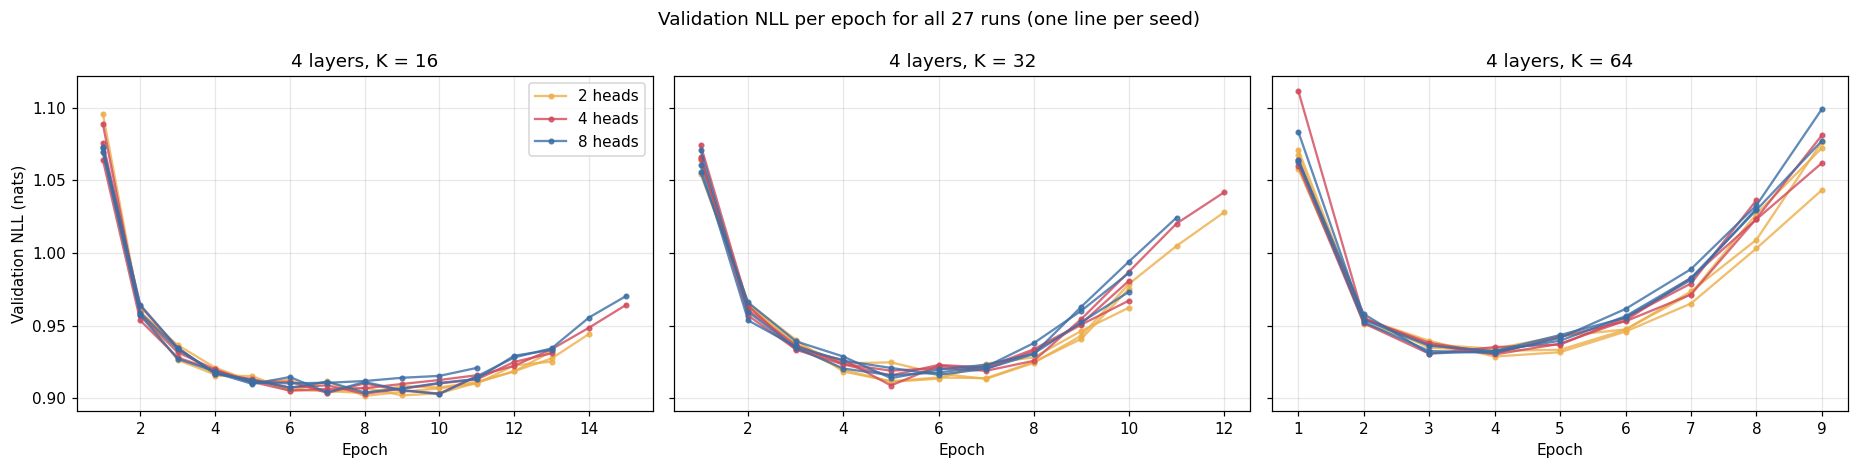

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.3), sharey=True)
colours = {2: "#edae49", 4: "#d1495b", 8: "#3b6ea5"}
for axis, context_length in zip(axes, GRID_CONTEXT):
    for n_heads in GRID_HEADS:
        for seed in SCREENING_SEEDS:
            history = analysis.load_history(all_run_dirs[config_id(N_LAYERS, n_heads, context_length, seed)])
            label = f"{n_heads} heads" if seed == SCREENING_SEEDS[0] else None
            axis.plot(history["epoch"], history["val_nll"], color=colours[n_heads], alpha=0.8, marker=".", label=label)
    axis.set_title(f"4 layers, K = {context_length}")
    axis.set_xlabel("Epoch")
axes[0].set_ylabel("Validation NLL (nats)")
axes[0].legend()
fig.suptitle("Validation NLL per epoch for all 27 runs (one line per seed)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "04_4L_validation_curves.png", bbox_inches="tight")
plt.show()

**Figure description.** Each panel shows the validation NLL after each epoch for one context length; colours distinguish head counts and each line is one seed. The lowest point of each line is the checkpoint retained for that run.

**Observation.** At K = 16 the curves reach a flat minimum between epochs 6 and 10 and rise only slowly afterwards. At K = 32 the minimum is reached around epoch 5 and the rise is steeper. At K = 64 the minimum is reached at epoch 3–4 and validation NLL then rises sharply (above 1.04 by epoch 9 for all seeds). Within a panel, the head counts are hardly distinguishable.

**Interpretation.** Under the fixed learning rate, longer windows lead to faster overfitting and a higher minimum. The difference between context lengths is therefore visible in the training dynamics and is not limited to the retained checkpoints. The figure does not identify why longer windows overfit sooner.

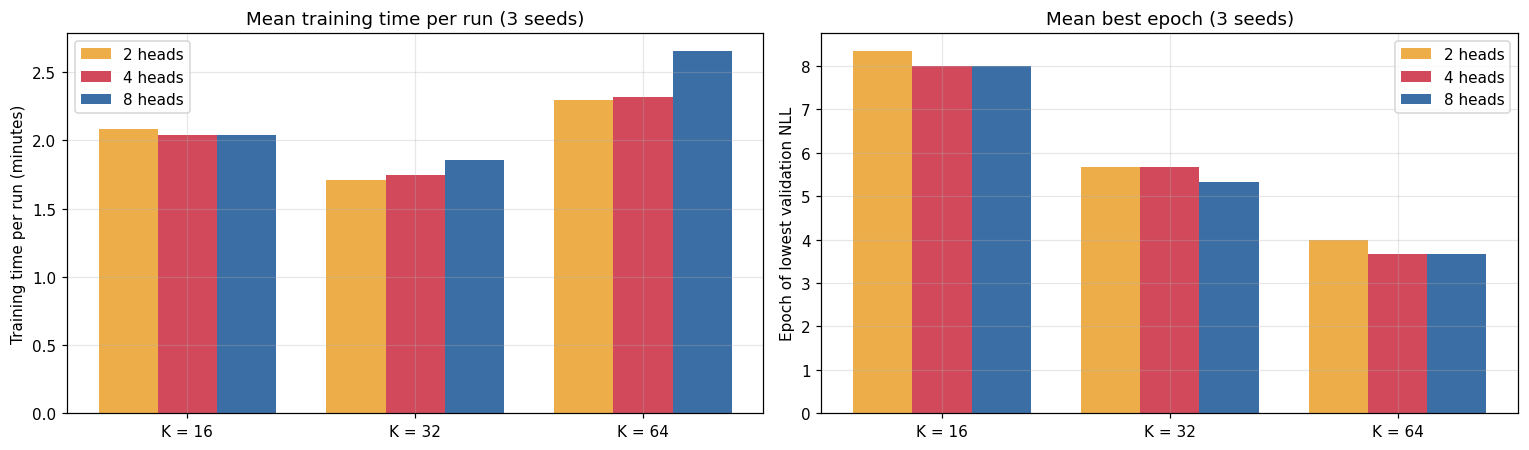

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
summary_time = seed_table.groupby(["heads", "K"])[["training_minutes", "best_epoch"]].mean().reset_index()
positions = np.arange(len(GRID_CONTEXT))
width = 0.26
for number, n_heads in enumerate(GRID_HEADS):
    subset = summary_time[summary_time["heads"] == n_heads].set_index("K").loc[GRID_CONTEXT]
    axes[0].bar(positions + (number - 1) * width, subset["training_minutes"], width=width, color=colours[n_heads],
                label=f"{n_heads} heads")
    axes[1].bar(positions + (number - 1) * width, subset["best_epoch"], width=width, color=colours[n_heads],
                label=f"{n_heads} heads")
for axis, ylabel, title in [(axes[0], "Training time per run (minutes)", "Mean training time per run (3 seeds)"),
                            (axes[1], "Epoch of lowest validation NLL", "Mean best epoch (3 seeds)")]:
    axis.set_xticks(positions)
    axis.set_xticklabels([f"K = {k}" for k in GRID_CONTEXT])
    axis.set_ylabel(ylabel)
    axis.set_title(title)
    axis.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "04_4L_training_cost.png", bbox_inches="tight")
plt.show()

**Figure description.** The left panel shows the mean wall-clock training time per run, including the final evaluation passes; the right panel shows the mean epoch at which the lowest validation NLL occurred.

**Observation.** Mean training time per run is about 2.0–2.1 minutes at K = 16, 1.7–1.9 minutes at K = 32 and 2.3–2.7 minutes at K = 64. The mean best epoch is about 8 at K = 16, 5–6 at K = 32 and 4 at K = 64.

**Interpretation.** The K = 32 runs are the fastest because early stopping ends them sooner than the K = 16 runs, while the K = 64 runs are the slowest despite stopping earliest, because each epoch is more expensive. The differences in cost are small in absolute terms (all runs take under three minutes on the GPU used), so training cost is not a deciding factor within the 4-layer grid. Timings were measured on a shared Colab GPU and are only approximately comparable.

## 8. Hyperparameter selection

The original notebook 04 selected the learning rate (3e-4) and weight decay (0.1) with a search on the 4L × 4H × K32 configuration. That search is not repeated. Re-tuning the learning rate for each configuration would confound the effect of the architecture with the effect of the optimisation settings. The inherited values were selected on a 4-layer model, so they do not place the 4-layer family at a disadvantage relative to the 2-layer results; configurations that would prefer different values may be slightly disadvantaged, which is recorded as a limitation in benchmark notebook 05.

## 9. Summary

* The current code reproduces the frozen Track A model exactly, and the re-run of 4L × 4H × K32 reproduces the Track A record exactly (mean validation NLL 0.9146).
* All 27 grid runs finished without divergence.
* Context length separates the configurations: K = 16 gives the lowest validation NLL for every head count, K = 64 the highest. Head count has a much smaller effect.
* The statistical comparison and the selection are carried out in benchmark notebook 05.